# 04 - MLP for purchase intention

- Goal: train the paper's multilayer perceptron with 10, 20 and 40 hidden neurons, with and without oversampling.

- Reproduces: paper Sections 2.2.1, 4.1.1, 4.1.2 and Tables 4, 7.

- Needs: nothing except utils.py. Writes results/mlp.csv, which notebook 06 reads.

- Expected run time: about 1.5 minutes on a GPU with 10 repeats (measured). A CPU would be slower.

## 1. Setup
QUICK_TEST = True runs a tiny version to check that the code works: 3 repeats, 1,500 rows and 2 epochs. It writes results/quick_mlp.csv instead of the real file.

In [2]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Windows: set before the other imports

import time

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from utils import (COLOURS, DEVICE, METRICS, compare_table, get_metrics, load_data, make_inputs,
                   paired_test, predict_mlp, save_results, set_style, show_table, split_data, train_mlp)

QUICK_TEST = False  # True: tiny run to check the code, not for results
N_REPEATS = 10  # paper uses 100
MAX_EPOCHS = 300
HIDDEN_SIZES = [10, 20, 40]
RESULT_NAME = "mlp"

if QUICK_TEST:
    N_REPEATS = 3
    MAX_EPOCHS = 2
    RESULT_NAME = "quick_mlp"

set_style()
df = load_data()
if QUICK_TEST:
    df = df.sample(1500, random_state=0)
X, y = make_inputs(df)
print("Device:", DEVICE, "| Input columns:", X.shape[1], "(paper: 70)")

Device: cuda | Input columns: 74 (paper: 70)


## 2. The model and its training
An MLP (multilayer perceptron) is a simple neural network. Ours has one hidden layer of sigmoid units, which output values between 0 and 1, as in paper Eq. 5. It has one sigmoid output, and we say "purchase" when that output is above 0.5. *See build_mlp in utils.py.*

We train with RPROP (resilient backpropagation), which gives each weight its own step size and uses only the sign of the gradient. We use all the training rows at each step and the summed squared error (paper Eqs. 1, 3 and 5). *See train_mlp in utils.py* . Training stops when the largest absolute gradient is below 0.2 (paper Section 2.2.1) or after MAX_EPOCHS.

**Deviation from the paper**: PyTorch's Rprop has no weight backtracking. The paper used RPROP with backtracking, which undoes the last step when a gradient changes sign. PyTorch only skips the update in that case.

**Deviation from the paper**: the paper does not limit the number of epochs. We stop at MAX_EPOCHS = 300, so a run may end before the gradient rule is met. The next section reports how often this happened.

## 3. Run all repeats
Every hidden size and setting uses the same splits as the baselines, because the seeds are the same.

In [2]:
start = time.time()
rows = []
epochs_used = []
for repeat in range(N_REPEATS):
    for setting, oversample in [("imbalanced", False), ("oversampled", True)]:
        X_tr, X_te, y_tr, y_te = split_data(X, y, seed=repeat, oversample=oversample)
        for hidden in HIDDEN_SIZES:
            model, epochs = train_mlp(X_tr, y_tr, hidden, seed=repeat, max_epochs=MAX_EPOCHS)
            scores = get_metrics(y_te, predict_mlp(model, X_te))
            rows.append({"model": f"MLP {hidden}", "setting": setting, "repeat": repeat, **scores})
            epochs_used.append(epochs)
            if QUICK_TEST:
                print(f"repeat {repeat} {setting} hidden {hidden}: F1 {scores['f1']:.3f}, {epochs} epochs")

res = save_results(rows, RESULT_NAME)
hit_cap = sum(e == MAX_EPOCHS for e in epochs_used)
print(f"Took {(time.time() - start) / 60:.1f} minutes")
print(f"Runs that hit MAX_EPOCHS: {hit_cap} of {len(epochs_used)}")

Took 1.5 minutes
Runs that hit MAX_EPOCHS: 60 of 60


All 60 of 60 runs hit the limit of 300 epochs. None of them reached the paper's stopping rule. So our networks may not have finished learning, and this could be part of why our results differ from the paper. We did not further test this.

## 4. Table 4: imbalanced setting
Here the models train on the data as it is. 
1. TPR (true positive rate) is the share of real buyers the model finds. 
2. TNR (true negative rate) is the share of non-buyers it labels correctly. 
3. F1 combines how many buyers the model finds with how many of its "buyer" guesses are right. 

In the table below, compare each of our columns with the paper's column beside it.


In [3]:
paper_imb = {"MLP 10": (87.45, 0.53, 0.94, 0.56), "MLP 20": (87.92, 0.56, 0.96, 0.58),
             "MLP 40": (87.02, 0.54, 0.93, 0.56)}
table = compare_table(res[res["setting"] == "imbalanced"], paper_imb)
show_table(table, f"Table 4: MLP, imbalanced setting, {N_REPEATS} repeats",
           best=["Accuracy %", "TPR", "TNR", "F1"])

,Accuracy %,Accuracy % (paper),TPR,TPR (paper),TNR,TNR (paper),F1,F1 (paper)
Model,,,,,,,,
MLP 10,88.53,87.45,0.58,0.53,0.94,0.94,0.61,0.56
MLP 20,87.82,87.92,0.57,0.56,0.93,0.96,0.59,0.58
MLP 40,87.62,87.02,0.56,0.54,0.93,0.93,0.58,0.56


We are close to the paper here. In our results, 10 hidden neurons is the best size on all four measures. In the paper, 20 is best on accuracy and F1. Our F1 values are slightly higher than the paper's for all three sizes.

## 5. Table 7: oversampled setting
Oversampling means copying rows of the smaller class in the train part until the two classes have the same size. Our test set keeps its natural 15.5% purchase rate. 

The paper's oversampled figures appear to fit a 50/50 test set (this is our reading, see notebook 03, section 6). So we also show accuracy and F1 converted to a 50/50 test set. Compare those values with the paper's.

In [4]:
paper_over = {"MLP 10": (87.24, 0.84, 0.92, 0.86), "MLP 20": (83.84, 0.84, 0.83, 0.83),
              "MLP 40": (82.15, 0.82, 0.83, 0.82)}
table = compare_table(res[res["setting"] == "oversampled"], paper_over, balanced=True)
show_table(table, f"Table 7: MLP, oversampled setting, {N_REPEATS} repeats",
           best=["Accuracy %", "TPR", "TNR", "F1", "Accuracy % (50/50 test)", "F1 (50/50 test)"])

,Accuracy %,Accuracy % (paper),TPR,TPR (paper),TNR,TNR (paper),F1,F1 (paper),Accuracy % (50/50 test),F1 (50/50 test)
Model,,,,,,,,,,
MLP 10,84.91,87.24,0.76,0.84,0.87,0.92,0.61,0.86,81.11,0.80
MLP 20,86.15,83.84,0.70,0.84,0.89,0.83,0.61,0.83,79.65,0.78
MLP 40,86.62,82.15,0.67,0.82,0.90,0.83,0.61,0.82,78.57,0.76


- On the 50/50 basis, 10 hidden neurons is our best size, as in the paper. 
- But our 81.11% is about 6 points below the paper's 87.24%, and our TPR of 0.76 is below the paper's 0.84. 
- Note that on natural-test accuracy the order flips: 40 neurons is highest (86.62%) and 10 is lowest (84.91%). This happens because the natural test set has many more non-buyers, so it rewards a high TNR.

## 6. Does the hidden size matter? Paired t-tests
A paired t-test compares two models one repeat at a time, on the same splits, so luck from the split cancels out. When we call a difference significant, we mean it is unlikely to be just chance. 

In this table, ** mean p < 0.01, * means p < 0.05, and N.S. means not significant.

In [5]:
part = res[res["setting"] == "oversampled"].sort_values("repeat")
pairs = []
for other in ["MLP 20", "MLP 40"]:
    out = {"Pair": f"MLP 10 vs {other}"}
    for metric in METRICS:
        out[metric] = paired_test(part[part["model"] == "MLP 10"][metric].values,
                                  part[part["model"] == other][metric].values)[1]
    pairs.append(out)
pd.DataFrame(pairs)

,Pair,accuracy,tpr,tnr,f1
0,MLP 10 vs MLP 20,**,**,**,N.S.
1,MLP 10 vs MLP 40,**,**,**,N.S.


- Our table uses natural-test values. On accuracy, TPR and TNR, the differences are unlikely to be just chance. But the direction is mixed: 10 neurons has higher TPR and lower TNR. Natural-test F1 shows no significant difference, with all three at 0.61. 
- The separate tests in notebook 06, section 6, use the 50/50 basis. There, 10 neurons beats 20 and 40 on accuracy and F1.

## 7. The four measures per hidden size
Each bar is the mean over repeats. Compare the left panel with the right panel, and look at TPR.

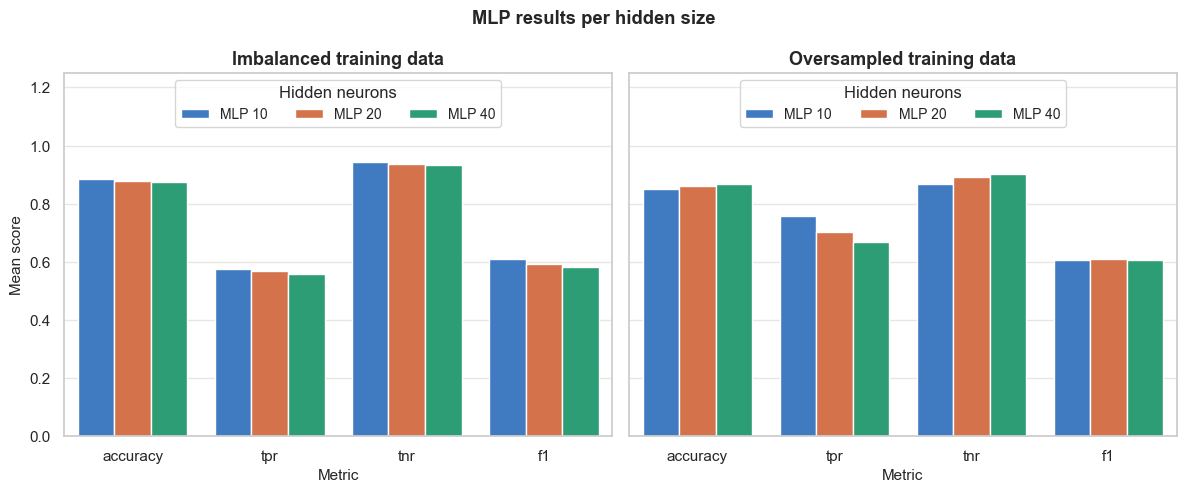

In [ ]:
long = res.melt(id_vars=["model", "setting"], value_vars=METRICS, var_name="metric")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, setting in zip(axes, ["imbalanced", "oversampled"]):
    sns.barplot(data=long[long["setting"] == setting], x="metric", y="value", hue="model",
                errorbar=None, palette=COLOURS[:3], ax=ax)
    ax.set_title(f"{setting.capitalize()} training data")
    ax.set_xlabel("Metric")
    ax.set_ylabel("Mean score")
    ax.set_ylim(0, 1.25)
    ax.legend(title="Hidden neurons", loc="upper center", ncol=3)

fig.suptitle("MLP results per hidden size", fontweight="bold")
plt.tight_layout()
plt.show()

Oversampling raises TPR for every size. It lifts MLP 10 from 0.58 to 0.76. 

It also lowers TNR, from 0.94 to 0.87 for MLP 10. So the network finds more buyers and makes more false alarms. 

The natural-test F1 hardly moves for MLP 10, which stays at 0.61.

## 8. Results at a glance
This uses 10 repeats. The oversampled row uses the 50/50 basis for accuracy and F1.

| Result | Ours | Paper | Compared with the paper |
|---|---|---|---|
| Imbalanced, MLP 10, accuracy % | 88.53 | 87.45 | close, slightly higher |
| Imbalanced, best F1 | 0.61 (10 neurons) | 0.58 (20 neurons) | close, different best size |
| Oversampled, MLP 10, accuracy % | 81.11 | 87.24 | lower |
| Oversampled, MLP 10, TPR | 0.76 | 0.84 | lower |
| Oversampled, MLP 10, TNR | 0.87 | 0.92 | lower |
| Oversampled, MLP 10, F1 | 0.80 | 0.86 | lower |

- Without oversampling, our MLP behaves much like the paper's. With oversampling, it is clearly weaker. 
- The paper and we agree that 10 hidden neurons is the best oversampled size on the 50/50 basis. 
- All 60 runs stopped at our 300-epoch limit, and PyTorch's RPROP has no backtracking. Either of these could explain the gap.

## 9. Key takeaways
1. We ran 10 repeats.

2. On imbalanced data, the best F1 is 0.61 with 10 hidden neurons (paper: 0.58 with 20).

3. With oversampling, the best hidden size is 10 on the 50/50 basis, as in the paper, while 40 is best on natural-test accuracy. 

4. 60 of 60 runs stopped at the epoch limit and not at the gradient rule, so training never reached the paper's stopping point.

So a smaller network also wins here on the 50/50 basis, but our result stays about 6 points below the paper. The difference between 10 neurons and the larger ones on accuracy and F1 is unlikely to be just chance (notebook 06, section 6). The missing weight backtracking and the 300-epoch limit could explain the gap, but we did not test either.